In [1]:
import pandas as pd
from pathlib import Path

# Works when Jupyter starts in either the project root or notebooks folder.
base = Path.cwd()
file_path = base / "data" / "expenses.csv"
if not file_path.is_file():
    file_path = base.parent / "data" / "expenses.csv"
if not file_path.is_file():
    raise FileNotFoundError("Open JupyterLab from the project folder and locate data/expenses.csv")

df = pd.read_csv(file_path)
df.head()

,date,category,amount
0,2026-10-01,Food,8
1,2026-10-01,Transport,3
2,2026-10-02,Books,18
3,2026-10-03,Food,9
4,2026-10-03,Transport,3


In [2]:
total = df["amount"].sum()

print("إجمالي المصروفات:", total)

إجمالي المصروفات: 139


In [3]:
categories = (
    df.groupby("category")["amount"]
    .sum()
    .sort_values(ascending=False)
)

print(categories)


category
Food             52
Entertainment    35
Books            33
Transport        19
Name: amount, dtype: int64


In [4]:
daily = df.groupby("date")["amount"].sum()

print("اليوم الأعلى إنفاقاً:")
print(daily.sort_values(ascending=False).head(1))

اليوم الأعلى إنفاقاً:
date
2026-10-02    18
Name: amount, dtype: int64


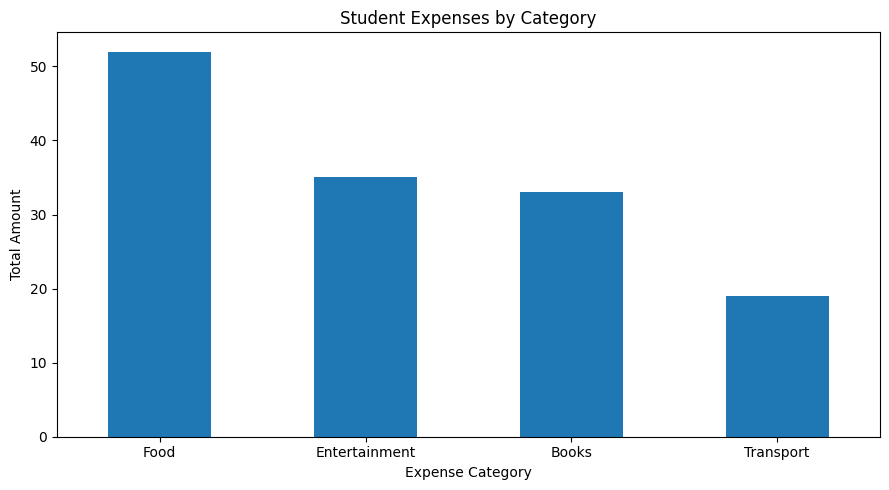

In [5]:
import matplotlib.pyplot as plt

category_totals = df.groupby("category")["amount"].sum().sort_values(ascending=False)
ax = category_totals.plot(kind="bar", figsize=(9, 5))
ax.set_title("Student Expenses by Category")
ax.set_xlabel("Expense Category")
ax.set_ylabel("Total Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(file_path.parent.parent / "expenses_chart.png", dpi=150)
plt.show()